# Exercise 02 Workbook: your own protein

This notebook is **deliberately almost empty**, and it is entirely about **your** protein: the
one on your ex01 Character Sheet, which you carry through ex03, ex04 and your final project.

Its companion, **`ex02_guide.ipynb`**, works everything through on human p53 and PDB 3D08.
**Read the guide first**, then work here with it open beside you. The sections below carry the
same numbers as the guide's: A.1 to A.3, then B.1 to B.3.

## How to work in this notebook

- **Copy code from the guide and adapt it.** Its helpers work on any protein with an
  AlphaFold DB entry.
- **Structure the notebook however you like.** The sections are a checklist, not a template.
- **The reasoning is graded, not the code.** Every section asks for a written conclusion.
- **No GPU here.** B.1's AlphaFold 3 run happens in ColabFold's notebook, on
  Colab's free GPU.

**Time: about 45 to 60 minutes**, plus the wait for AlphaFold 3. **What you will not learn
here** is anything the guide did not show: every section asks for a guide step, repeated on
your protein.

## Using AI tools

You may use AI assistants for syntax, debugging and code snippets. You must supply the
predictions, the critical evaluation and the biological reasoning. **"The AI said so" is not
an answer.**

**Predict-first prompts** (A.1 and B.1) ask for your prediction *before* you run
anything. That written prediction is the graded artefact. Being wrong costs nothing; not
predicting costs the marks.

## Setup

Copy the guide's setup cell here and run it first. A Colab notebook starts empty, so
nothing from the guide's session carries over here.

In [1]:
#@title Setup {display-mode: "form"}
# Setup. Everything in this notebook runs on a plain CPU runtime.
try:
    from google.colab import drive  # noqa: F401  (import is the availability test)

    is_google_colab = True
except ImportError:
    is_google_colab = False

if is_google_colab:
    %pip install numpy==2.1.3 pandas==2.2.3 matplotlib==3.10.0 py3dmol==2.4.0 mdanalysis==2.10.0 biopython==1.85 rdkit==2026.3.5

import warnings

warnings.filterwarnings("ignore")

import json
import os
import re
import tempfile
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import MDAnalysis as mda
import numpy as np
import pandas as pd
import py3Dmol
import requests
from Bio.PDB import PDBIO, MMCIFParser
from MDAnalysis.analysis import align, distances
from rdkit import Chem
from rdkit.Chem import rdMolAlign

print("Libraries loaded -- no GPU needed")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.9/108.9 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 64.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 74.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.4/37.4 MB 15.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 71.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 4.7 MB/s eta 0:00:00


Libraries loaded -- no GPU needed


---

## Your structure: the crystal from ex01

This notebook works on **the crystal you chose in ex01**, the PDB entry on your Character
Sheet, and on no other: not another entry of the same protein, even a sharper one. The
residue numbers you carry from one exercise to the next belong to that entry. Every
candidate numbers its residues the way UniProt does, so they also line up with both AlphaFold models, as long as B.1 gets your whole
UniProt sequence.

Put its PDB ID at the top of your first code cell, as `PDB_ID = "..."`, and use `PDB_ID`
wherever the guide names its own entry.

---

# Part A: Your protein's AlphaFold prediction

## A.1 Predict first, before you fetch anything

**Before you look at any number**, predict: will confidence be uniform or split, and where?
Base it on your ex01 findings: the residues your crystal failed to resolve, and those with the
highest B-factors. A wrong prediction with stated reasoning earns full marks; "I don't know"
earns none.

Protein missing from [the AlphaFold Database](https://alphafold.ebi.ac.uk/)? Use the
[AlphaFold Server](https://alphafoldserver.com/welcome) or
[ColabFold](https://colab.research.google.com/github/sokrypton/ColabFold/blob/main/AlphaFold2.ipynb).

> **My prediction:** The AlphaFold prediction is not uniform. Low confidence score at both ends while moderate to high confidence for the rest.
>
> **My reasoning (citing my ex01 findings):** 1STD has the X-ray diffraction solved for a 162-aa long subunit while the deposited residue count is 172. The first 8 amino acid at amino terminus and the last 2 at carboxyl terminus are not modelled due to the lack of electron density. I think the AlphaFold prediction will return low confidence score for these two regions. Though the amino acid with high B-factor means that the atom motion is dynamic, the electron density is still there so I guess the AlphaFold is able to predict its structure with good confidence.

## A.2 Confidence analysis

Produce, for your protein: the global mean pLDDT, a per-residue **pLDDT plot**, a **PAE
heatmap** and the four `fractionPlddt*` bands.

> Information about Prediction for 1STD (P56221):
https://alphafold.ebi.ac.uk/api/prediction/P56221

| Category | Score |
|---|---|
| `globalMetricValue` | 93.5 |
| `fractionPlddtVeryLow` | 0.012 |
| `fractionPlddtLow` | 0.041 |
| `fractionPlddtConfident` | 0.105 |
| `fractionPlddtVeryHigh` | 0.843 |
| `organismScientificName` | Pyricularia oryzae |

> Clarification: in the previous exercise, *Magnaporthe grisea* was mentioned as the pathogenic fungus in rice blast disease. However, UniProt reported *Pyricularia oryzae* (also known as *Magnaporthe oryzae*). This is due to the phylogenetic reconstruction in 2002¹, in which the tree inferred using portions of three genes (actin, beta-tubulin and calmodulin) distinguished two distinct clades within *Magnaporthe grisea* in which one was associated with Oryza sativa and then described as *Magnaporthe oryzae*.
**Then answer:**

- Where is pLDDT above 90, and where below 70? Why there: core, surface, loops, termini?
> Active and binding sites span 11-51 and 56-158 residues have pLDDT > 90 meaning that in this region the AlphaFold prediction strongly agrees with the experimental structure (including highly flexible residues detected in exercise 1), while the other positions have pLDDT < 70, especially the uncrystallized terminal residues at 1-8, 171-172 and K56. Low pLDDT can be due to lack of information for prediction, intrinsic disorder or high flexibility. In this case, the low confidence conincide with the missing residues in crystal structure of 1STD due to the absence of electron density.

- Which parts does the PAE place confidently relative to each other, and which not?
> Low PAE score indicates strong confidence about the packaging of 162 residues (1-170) in folding space, however, expected distance error is incredibly high in N terminus showing that it was unsure about the exact arrangement of those amino acids relative to the rest of the domain, meaning that the position of these residues are essentially random. Moreover, considerable number of C-terminal residues also show the substantial error, conveying AlphaFold's hesitation in predicting their exact arrangement.   

- Is your protein uniformly mediocre, or excellent in one region and uncertain elsewhere?
> My protein in general is uniform in the the regions which have crystal evidence, while the terminal regions are uncertain.

- How did your A.1 prediction hold up? If it was wrong, what did you miss?
> My prediction is close to the AlphaFold's prediction in which low confidence at both termini. However, AlphaFold's prediction (PAE) provides the spatial information that I was not able to predict.

1. Couch BC, Kohn LM. A multilocus gene genealogy concordant with host preference indicates segregation of a new species, Magnaporthe oryzae, from M. grisea. Mycologia. 2002

In [2]:
def prediction_record(uniprot: str, fragment: int = 1) -> pd.Series:
    """AlphaFold DB's record for one UniProt accession, as a single row.

    The record carries the summary metrics and the URLs of every other file, so nothing
    below ever builds an AlphaFold DB URL by hand. Very long proteins come back as more
    than one fragment; most, including p53, fit in `F1`.
    """
    entries = pd.json_normalize(
        requests.get(f"https://alphafold.ebi.ac.uk/api/prediction/{uniprot}").json()
    )
    return entries.set_index("modelEntityId").loc[f"AF-{uniprot}-F{fragment}"]


def download_prediction_files(entry: pd.Series, directory: Path) -> dict[str, Path]:
    """Save the three files the record points at. Returns {name: path}.

    A URL the database does not serve is reported and skipped rather than stopping the
    download of the others.
    """
    directory.mkdir(exist_ok=True)
    wanted = {"model.pdb": "pdbUrl", "confidence.json": "plddtDocUrl", "pae.json": "paeDocUrl"}
    saved = {}
    for name, field in wanted.items():
        response = requests.get(entry[field])
        target = directory / f"{entry.name}-{name}"
        if response.status_code != 200:
            print(f"    {name:<18} HTTP {response.status_code}  <-- unavailable, skipped")
            continue
        target.write_bytes(response.content)
        saved[name] = target
        print(f"    {name:<18} {len(response.content):>9,} bytes  -> {target}")
    return saved


def per_residue_confidence(entry: pd.Series) -> pd.DataFrame:
    """PLDDT and its confidence category, indexed by residue number.

    The file is three parallel arrays, which is already a table. Indexing by residue
    number means slicing a range later reads like the biology.
    """
    return (
        pd.read_json(entry["plddtDocUrl"])
        .rename(columns={"confidenceScore": "pLDDT", "confidenceCategory": "category"})
        .set_index("residueNumber")
    )


def pae_matrix(entry: pd.Series) -> pd.DataFrame:
    """The n x n predicted aligned error, indexed by residue number on both axes."""
    record = pd.read_json(entry["paeDocUrl"]).iloc[0]
    pae = pd.DataFrame(record["predicted_aligned_error"])
    pae.index += 1              # residue numbering starts at 1, not 0
    pae.columns += 1
    return pae


def confidence_bands(entry: pd.Series) -> pd.Series:
    """The four fractionPlddt* bands, as a Series labelled by their pLDDT range."""
    labels = {
        "fractionPlddtVeryLow": "Very low (<50)",
        "fractionPlddtLow": "Low (50-70)",
        "fractionPlddtConfident": "Confident (70-90)",
        "fractionPlddtVeryHigh": "Very high (>90)",
    }
    return pd.Series({label: entry[field] for field, label in labels.items()})


In [4]:
UNIPROT = "P56221"
DATA = Path("afdb_data")
DATA.mkdir(exist_ok=True)

entry = prediction_record(uniprot=UNIPROT)
(DATA / f"afdb_{UNIPROT}.json").write_text(entry.to_json(indent=2))

print(f"Model: {entry.name}  (pipeline: {entry['toolUsed']})")
print(f"Sequence length: {entry['sequenceEnd'] - entry['sequenceStart'] + 1} residues")
print(f"Global mean pLDDT: {entry['globalMetricValue']:.1f}\n")

print("  provenance, and the fields used below:")
for key in ("modelCreatedDate", "latestVersion", "uniprotSequence", "globalMetricValue",
            "pdbUrl", "plddtDocUrl", "paeDocUrl"):
    if key in entry:
        value = entry[key]
        shown = f"{value[:52]}..." if isinstance(value, str) and len(value) > 55 else value
        print(f"    {key:<20} {shown}")

print("\n  downloading:")
files = download_prediction_files(entry=entry, directory=DATA)

Model: AF-P56221-F1  (pipeline: AlphaFold Monomer v2.0 pipeline)
Sequence length: 172 residues
Global mean pLDDT: 93.5

  provenance, and the fields used below:
    modelCreatedDate     2025-08-01T00:00:00Z
    latestVersion        6
    uniprotSequence      MGSQVQKSDEITFSDYLGLMTCVYEWADSYDSKDWDRLRKVIAPTLRIDYRS...
    globalMetricValue    93.5
    pdbUrl               https://alphafold.ebi.ac.uk/files/AF-P56221-F1-model...
    plddtDocUrl          https://alphafold.ebi.ac.uk/files/AF-P56221-F1-confi...
    paeDocUrl            https://alphafold.ebi.ac.uk/files/AF-P56221-F1-predi...

  downloading:
    model.pdb            120,932 bytes  -> afdb_data/AF-P56221-F1-model.pdb
    confidence.json        2,337 bytes  -> afdb_data/AF-P56221-F1-confidence.json
    pae.json              63,136 bytes  -> afdb_data/AF-P56221-F1-pae.json


In [5]:
# Read each file back from disk and show its actual shape. Everything after this cell
# goes through the helpers instead; this is the one look at the raw files.
conf = json.loads(files["confidence.json"].read_text())
print("confidence.json")
print(f"  keys        : {list(conf.keys())}")
print(f"  n residues  : {len(conf['residueNumber'])}")
print(f"  first 5     : residue {conf['residueNumber'][:5]}")
print(f"                score   {conf['confidenceScore'][:5]}")
print(f"                category{conf['confidenceCategory'][:5]}   (D/L/M/H = disordered->high)")

pae_obj = json.loads(files["pae.json"].read_text())[0]
print("\npae.json")
print(f"  keys        : {list(pae_obj.keys())}")
print(f"  matrix      : {len(pae_obj['predicted_aligned_error'])} x "
      f"{len(pae_obj['predicted_aligned_error'][0])}")
print(f"  max_predicted_aligned_error = {pae_obj['max_predicted_aligned_error']}")

atom_lines = [line for line in files["model.pdb"].read_text().splitlines()
              if line.startswith("ATOM")]
print("\nmodel.pdb")
print(f"  ATOM records: {len(atom_lines):,}")
print(f"  first ATOM  : {atom_lines[0][:66]}")
print("                                                     ^^^^^^ B-factor column = pLDDT")

# Prove the B-factor column really is the pLDDT from confidence.json
first_ca = next(line for line in atom_lines if line[12:16].strip() == "CA")
print(f"\n  residue 1 pLDDT from confidence.json : {conf['confidenceScore'][0]}")
print(f"  residue 1 B-factor from model.pdb    : {float(first_ca[60:66])}")


confidence.json
  keys        : ['residueNumber', 'confidenceScore', 'confidenceCategory']
  n residues  : 172
  first 5     : residue [1, 2, 3, 4, 5]
                score   [40.16, 49.34, 57.81, 50.03, 54.59]
                category['D', 'D', 'L', 'L', 'L']   (D/L/M/H = disordered->high)

pae.json
  keys        : ['predicted_aligned_error', 'max_predicted_aligned_error']
  matrix      : 172 x 172
  max_predicted_aligned_error = 31.75

model.pdb
  ATOM records: 1,430
  first ATOM  : ATOM      1  N   MET A   1     -34.826  -8.244  33.200  1.00 40.16
                                                     ^^^^^^ B-factor column = pLDDT

  residue 1 pLDDT from confidence.json : 40.16
  residue 1 B-factor from model.pdb    : 40.16


In [55]:
def plot_plddt(confidence: pd.DataFrame, highlight: tuple[int, int] | None = None,
               title: str | None = None, ax: plt.Axes | None = None,
               label: str = "AlphaFold DB") -> plt.Axes:
    """PLDDT along the sequence. `highlight` shades a (start, end) residue range."""
    if ax is None:
        _, ax = plt.subplots(figsize=(12, 4))
    ax.plot(confidence.index, confidence["pLDDT"], color="tab:blue", lw=1, label=label)
    ax.axhline(90, color="grey", ls=":", lw=1, label="pLDDT = 90 (very high)")
    ax.axhline(70, color="grey", ls="--", lw=1, label="pLDDT = 70 (confident cutoff)")
    if highlight is not None:
        ax.axvspan(highlight[0], highlight[1], color="tab:green", alpha=0.15,
                   label=f"resolved range ({highlight[0]}-{highlight[1]})")
    ax.set_xlabel("Residue number")
    ax.set_ylabel("pLDDT")
    ax.set_ylim(0, 100)
    ax.set_title(title or "AlphaFold DB per-residue confidence")
    ax.legend(loc="lower center")
    return ax


def plot_pae(pae: pd.DataFrame | np.ndarray,
             title: str = "Predicted Aligned Error (PAE)",
             ax: plt.Axes | None = None) -> plt.Axes:
    """The PAE matrix as a heatmap, dark = confident.

    Row i, column j is the error at residue j when the structures are aligned on residue
    i. Takes the DataFrame from `pae_matrix` or a plain array, such as AlphaFold 3's `pae`.
    """
    values = np.asarray(pae)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(values, cmap="Greens_r", vmin=0, vmax=values.max(),
                   extent=[1, values.shape[1], values.shape[0], 1])
    ax.set_xlabel("Scored residue")
    ax.set_ylabel("Aligned residue")
    ax.set_title(title)
    ax.figure.colorbar(im, ax=ax, label="Expected error (A)")
    return ax

def local_confidence(start : int, end : int) -> str:
    """Returns the pLDDT around the specified region"""
    core = confidence.loc[start:end, "pLDDT"]
    print(f"AlphaFold mean pLDDT over 1STD's resolved range "
      f"({start}-{end}): {core.mean():.1f}")
    print(f"Fraction of that range with pLDDT < 70: {(core < 70).mean()*100:.1f}%")
    region = end - start
    if region > 10:
      print(f"\npLDDT right around specified position {start}-{end} (show first 5 rows)")
      print(confidence.loc[start:end].head().to_string(), "\n")
    else:
      print(f"\npLDDT right around specified position {start}-{end}")
      print(confidence.loc[start:end].to_string(), "\n")



In [56]:
confidence = per_residue_confidence(entry=entry)

print("UNMODELLED FRACTION")
local_confidence(start = 1, end = 8)
local_confidence(start = 171, end = 172)

print("BFS-BIDNING FRACTION")
local_confidence(start = 30, end = 127)


UNMODELLED FRACTION
AlphaFold mean pLDDT over 1STD's resolved range (1-8): 54.6
Fraction of that range with pLDDT < 70: 87.5%

pLDDT right around specified position 1-8
               pLDDT category
residueNumber                
1              40.16        D
2              49.34        D
3              57.81        L
4              50.03        L
5              54.59        L
6              55.00        L
7              58.69        L
8              71.56        M 

AlphaFold mean pLDDT over 1STD's resolved range (171-172): 58.9
Fraction of that range with pLDDT < 70: 100.0%

pLDDT right around specified position 171-172
               pLDDT category
residueNumber                
171            67.06        L
172            50.81        L 

BFS-BIDNING FRACTION
AlphaFold mean pLDDT over 1STD's resolved range (30-127): 96.9
Fraction of that range with pLDDT < 70: 0.0%

pLDDT right around specified position 30-127 (show first 5 rows)
               pLDDT category
residueNumber           

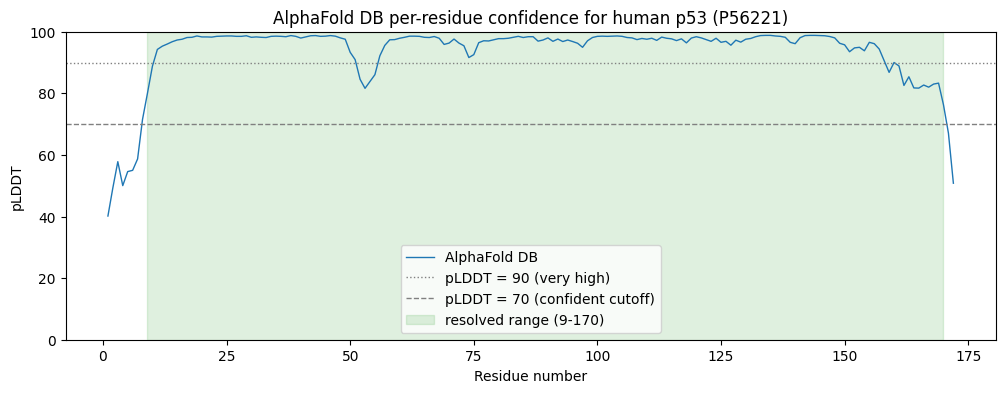

In [47]:
CRYSTAL_START = 9
CRYSTAL_END = 170
plot_plddt(confidence=confidence, highlight=(9, 170),
           title=f"AlphaFold DB per-residue confidence for human p53 ({UNIPROT})")
plt.show()

In [103]:
pos = sorted(confidence.loc[confidence["pLDDT"] > 90].index.to_list())
print(f"residues with pLDDT > 90: {pos[0]}-{pos[-1]}")

gap = list()
pos0 = pos[0]
for i in range(len(pos)):
  diff = pos[i] - pos0
  if diff == 0 or diff == 1:
    pos0 = pos[i]
    continue
  else:
    pos0 = pos[i]
    gap.append([pos[i-1], pos[i]])

print(f"Middle drop in pLDDT at position {gap}")

residues with pLDDT > 90: 11-158
Middle drop in pLDDT at position [[51, 56]]


PAE matrix: 172 x 172 residues
Largest expected error in this entry: 31.0 A


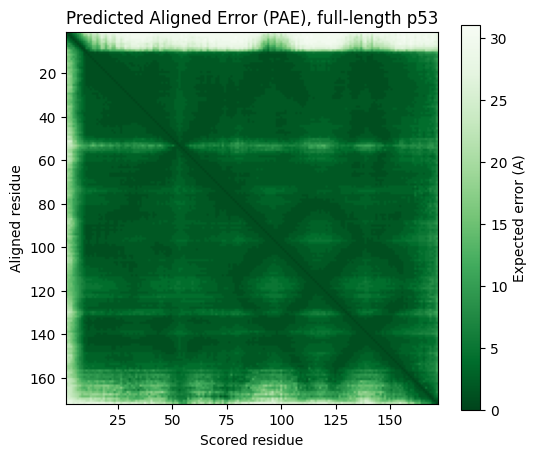


Mean PAE within the core domain  : 2.9 A
Mean PAE core vs. N-terminal tail : 12.9 A


In [48]:
pae = pae_matrix(entry=entry)
print(f"PAE matrix: {pae.shape[0]} x {pae.shape[1]} residues")
print(f"Largest expected error in this entry: {pae.values.max():.1f} A")

plot_pae(pae=pae, title="Predicted Aligned Error (PAE), full-length 1STD")
plt.show()

# Because it is a DataFrame indexed by residue, questions about regions are one line each:
core_block = pae.loc[CRYSTAL_START:CRYSTAL_END, CRYSTAL_START:CRYSTAL_END]
print(f"\nMean PAE within the core domain  : {core_block.values.mean():.1f} A")
print(f"Mean PAE core vs. N-terminal tail : "
      f"{pae.loc[CRYSTAL_START:CRYSTAL_END, 1:CRYSTAL_START-1].values.mean():.1f} A")

In [104]:
bands = confidence_bands(entry=entry)

print(f"Mean pLDDT {entry['globalMetricValue']:.1f} is made of:")
for label, fraction in bands.items():
    print(f"  {label:<20} {fraction*100:5.1f}%  {'#' * int(fraction * 50)}")

usable = bands["Confident (70-90)"] + bands["Very high (>90)"]
print(f"\n  above 70 (usable): {usable*100:.1f}%")
print(f"  below 70         : {(1 - usable)*100:.1f}%")

Mean pLDDT 93.5 is made of:
  Very low (<50)         1.2%  
  Low (50-70)            4.1%  ##
  Confident (70-90)     10.5%  #####
  Very high (>90)       84.3%  ##########################################

  above 70 (usable): 94.8%
  below 70         : 5.2%


## A.3 The AlphaFold model against your crystal

Superimpose the AlphaFold DB model on your ex01 crystal (`PDB_ID`) as the guide does. Report the
overall Cα RMSD, over how many matched residues, and the highest-deviation regions.

**Then answer:** why do those regions differ? An unresolved crystal loop nearby, a mutation, a
bound ligand or ion the model lacks, or a genuinely wrong prediction?

If your protein has no AlphaFold DB entry, **say so** rather than forcing the comparison. That
is a real outcome, not a failure.

> After the AlphaFold prediction, stuctural alignment of both crystal and predicted structure will provide a detailed description how close the prediction is close to the experimental by measuring the root mean square deviation (RMSD) between alpha-carbon backbone atoms of two superimposed protein structures. The overall C-alpha RMSD is 1.10 Å, indicating that the fold-level prediction is highly structural similar to the crystal. RMSD of active and binding sites, which are critical for the enzyme, is rather small, i.e HIS85 (0.89 Å) and TYR50 (0.20 Å). I have observed that though AlphaFold was uncertain about the local distance of backbond and side chain and the displacement of K56 but the superimposition shows that the prediction is quite close to the experiemental (0.11 Å). Though E97 was predicted with high confidence, there is a disagreement between the predicted and crystal about the folding of E97. The largest deviation falls at the C terminus 159-156 and 170 (> 2.2 Å) in which Alphafold proposes a flexible fold while the crystal folds into helix, while highly flexible residues 118, 119, and 126 show moderate deviation (1.62-1.65 Å). Several possible explanations for the largest deviation is that (1) both crystal and predicted structures are just one static snapshot out of multiple possiblities as protein under different condition will possess different folding properties; in X-crystallography, protein molecule is packed tightly into a crystal lattice which can cause artificial loop and surface shift; while Alphafold predicts the structure in an ideal condition. (2) the regions are highly flexible (large crystal b-factor), hence the coordinates can be imprecise; (3) crystal structure was solved with ligand which can change the enzyme confirmation while AlphaFold predicts the no-ligand state of it.

In [106]:
def fetch_pdb(pdb_id: str, path: str | None = None) -> str:
    """Download one PDB entry next to the notebook, once. Returns the local path.

    Fetched with Python rather than wget, so this works identically on Colab, in a local
    conda environment, and in a container: the download is not a Colab-only step.
    MDAnalysis reads structures but does not retrieve them, so this stays plain urllib.
    """
    path = path or f"{pdb_id}.pdb"
    if not os.path.exists(path):
        urllib.request.urlretrieve(f"https://files.rcsb.org/download/{pdb_id}.pdb", path)
        print(f"Downloaded {path} from RCSB")
    else:
        print(f"{path} already present")
    return path


def read_structure(path: str | Path) -> mda.AtomGroup:
    """A PDB or mmCIF file as MDAnalysis atoms, one conformation per atom.

    MDAnalysis reads PDB but not mmCIF, so an mmCIF file, such as AlphaFold 3's model, is
    first rewritten as PDB beside it. Chain and residue numbers are the author ones, which
    for AlphaFold 3 count along the sequence you pasted. Where a crystal models an atom in
    alternate positions, only position A is kept: left in, that atom would count twice.
    Atoms with no alternates leave the field blank, and `not altloc ?` is how to say so.
    """
    path = Path(path)
    if path.suffix == ".cif":
        writer = PDBIO()
        writer.set_structure(MMCIFParser(QUIET=True).get_structure(path.stem, path))
        path = path.with_suffix(".pdb")
        writer.save(str(path))
    return mda.Universe(path).select_atoms("altloc A or not altloc ?")


def superpose(mobile: mda.AtomGroup, reference: mda.AtomGroup,
              chain: str = "A") -> tuple[float, pd.Series]:
    """Move `mobile` onto `reference`. Returns the CA RMSD and each residue's deviation.

    The fit uses the CA atoms of the residues both structures have: it is the rotation and
    shift that make their RMSD smallest, and that RMSD is the root mean square of the
    per-residue deviation returned beside it. Every atom of `mobile` moves with the fit,
    ligands included, so the two structures can then be measured and viewed in one frame.

    Matching is by residue NUMBER, not by list position: a crystal with unresolved loops
    is not a gap-free span, and pairing by position would silently misalign everything
    after the first gap.
    """
    ca = f"protein and name CA and chainID {chain}"
    shared = sorted(set(mobile.select_atoms(ca).resids)
                    & set(reference.select_atoms(ca).resids))
    pairs = f"{ca} and resid {' '.join(map(str, shared))}"
    _, rmsd = align.alignto(mobile, reference, select=pairs)     # RMSD before, and after
    moved, fixed = mobile.select_atoms(pairs), reference.select_atoms(pairs)
    deviation = pd.Series(distances.dist(moved, fixed)[2],       # atom-by-atom distances
                          index=pd.Index(fixed.resids, name="residue_number"),
                          name="deviation (A)")
    return float(rmsd), deviation


def pdb_text(atoms: mda.AtomGroup) -> str:
    """The atoms as PDB text: what py3Dmol and RDKit read, where MDAnalysis holds objects."""
    with tempfile.NamedTemporaryFile(suffix=".pdb") as handle:
        atoms.write(handle.name, bonds=None)
        return Path(handle.name).read_text()


def show_superposition(reference: mda.AtomGroup, mobile: mda.AtomGroup,
                       highlight: list[int] | tuple[int, ...] = (),
                       ligand: str | None = None, width: int = 900,
                       height: int = 550) -> py3Dmol.view:
    """A crystal and an AlphaFold model in one view: `highlight` as sticks, `ligand` as spheres.

    `reference`, the crystal, is neon green. `mobile`, the model, takes AlphaFold's own
    confidence colours, atom by atom, from the pLDDT in its B-factor column: dark blue
    above 90, light blue from 70, yellow from 50, orange below.
    """
    view = py3Dmol.view(width=width, height=height)
    for atoms in (reference, mobile):
        view.addModel(pdb_text(atoms=atoms), "pdb")

    colored = [({"model": 0}, "#39FF14")]
    for low, high, color in ((90, 101, "#0053D6"), (70, 90, "#65CBF3"),
                             (50, 70, "#FFDB13"), (0, 50, "#FF7D45")):
        in_band = (mobile.tempfactors >= low) & (mobile.tempfactors < high)
        if in_band.any():
            # The PDB text numbers its atoms 1, 2, 3, ... in the order they sit in `mobile`.
            serials = (np.flatnonzero(in_band) + 1).tolist()
            colored.append(({"model": 1, "serial": serials}, color))

    for atoms, color in colored:
        view.setStyle(atoms, {"cartoon": {"color": color}})
        if len(highlight):
            view.addStyle({**atoms, "resi": list(highlight)}, {"stick": {"color": color}})
        if ligand:
            view.addStyle({**atoms, "resn": ligand},
                          {"sphere": {"color": color, "radius": 0.6}})
    view.zoomTo({"model": 0, "resi": list(highlight)} if len(highlight) else {})
    return view

In [108]:
# AlphaFold's model is already on disk from the download above; the crystal is one call.
af_model = read_structure(path=files["model.pdb"])
crystal = read_structure(path=fetch_pdb(pdb_id="1STD", path=f"{DATA}/1STD.pdb"))

af_ca = af_model.select_atoms("protein and name CA").resids
crystal_ca = crystal.select_atoms("protein and name CA and chainID A").resids
print(f"AlphaFold model: {len(af_ca)} CA atoms, range {af_ca.min()}-{af_ca.max()}")
print(f"1STD crystal: {len(crystal_ca)} CA atoms, range {crystal_ca.min()}-{crystal_ca.max()}")

unresolved = sorted(set(range(crystal_ca.min(), crystal_ca.max() + 1)) - set(crystal_ca.tolist()))
print(f"Matched (by residue number) residues: {len(set(af_ca) & set(crystal_ca))}")
print(f"Residues with no crystal coordinates inside that range (unresolved loops): {unresolved}")

afdb_data/1STD.pdb already present
AlphaFold model: 172 CA atoms, range 1-172
1STD crystal: 162 CA atoms, range 9-170
Matched (by residue number) residues: 162
Residues with no crystal coordinates inside that range (unresolved loops): []


In [129]:
# Superpose the AlphaFold model on the crystal, then read the deviation residue by
# residue: the overall number hides where the disagreement actually is.
overall_rmsd, deviation = superpose(mobile=af_model, reference=crystal)

print(f"Overall CA RMSD over {len(deviation)} matched residues: {overall_rmsd:.2f} Å")

print("\nHighest-deviation residues:")
print(deviation.nlargest(10).round(2).to_string())

print("\nDeviation at BFS-binding positions:")
sites =  ((30, "Y30"), (50, "Y50"), (85, "H85"), (110, "H110"), (56, "K56"),
          (162, "F162"), (76, "L76"), (147, "L147"), (149, "P149"), (131, "N131"))
for position, substitution in sites:
    print(f"  {substitution}: {deviation.get(position, float('nan')):.2f} Å")

Overall CA RMSD over 162 matched residues: 1.10 Å

Highest-deviation residues:
residue_number
156    7.71
155    7.42
157    2.98
158    2.46
159    2.39
118    1.65
97     1.64
119    1.63
126    1.62
170    1.46

Deviation at BFS-binding positions:
  Y30: 0.47 Å
  Y50: 0.20 Å
  H85: 0.89 Å
  H110: 0.39 Å
  K56: 0.11 Å
  F162: 0.29 Å
  L76: 0.74 Å
  L147: 0.32 Å
  P149: 0.30 Å
  N131: 0.67 Å


In [126]:
# superpose() moved every atom of the AlphaFold model, not only its CA atoms, so the two
# structures already share one frame: overlay them and zoom on what is worth looking at.
show_superposition(reference=crystal, mobile=af_model,
                   highlight=deviation.nlargest(10).round(2).index.to_list(),
                   ligand="BFS").show()
print("Green = 1STD crystal. AlphaFold's WT model (no "
      "ligand) is coloured by pLDDT:\ndark blue above 90, light blue 70 to 90, yellow 50 to "
      "70, orange below 50.")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Green = 1STD crystal. AlphaFold's WT model (no ligand) is coloured by pLDDT:
dark blue above 90, light blue 70 to 90, yellow 50 to 70, orange below 50.


---

# Part B: AlphaFold 3, with your ligand

## B.1 Predict, then run AlphaFold 3

**Before you run anything**, predict: where will AlphaFold 3 put your ex01 ligand, and how
sure will it be? Base it on your ex01 contact residues and your A.3 deviations near them.

Then run AlphaFold 3 in ColabFold's notebook as the guide's B.1 does, with your whole UniProt
sequence and your ligand's CCD code.

> **My prediction:** I think AlphaFold3 will predict the interaction with high confidence.
>
> **My reasoning (citing my ex01 contacts and A.3):** because the RMSD in BFS-binding sites are relatively small.

In [130]:
# The exact string for ColabFold's `protein` box: the whole UniProt sequence, which the
# AlphaFold DB record already carries, on one line so that it pastes cleanly.
print(f"{UNIPROT}, {len(entry['uniprotSequence'])} residues -- copy the line below:\n")
print(entry["uniprotSequence"])

P56221, 172 residues -- copy the line below:

MGSQVQKSDEITFSDYLGLMTCVYEWADSYDSKDWDRLRKVIAPTLRIDYRSFLDKLWEAMPAEEFVGMVSSKQVLGDPTLRTQHFIGGTRWEKVSEDEVIGYHQLRVPHQRYKDTTMKEVTMKGHAHSANLHWYKKIDGVWKFAGLKPDIRWGEFDFDRIFEDGRETFGDK


## B.2 What AlphaFold 3 returns

Upload your ZIP and unpack it as the guide does. Report `ranking_score`, `ptm`, the
protein-ligand `chain_pair_iptm` and `chain_pair_pae_min`, your ligand's mean pLDDT, and
AlphaFold 3's per-residue pLDDT drawn over your A.2 curve.

**Then answer:** which of these numbers is about your ligand, and what does each say? Where
do the two pLDDT curves part, and why might they?

> The overall predicted complex pTM 0.86 proposes a high similarity with the hypothetical true structure. High ipTM 0.9 shows that the predicted relative positions of the protein-ligand complex is quite accurate. The accuracy of protein-ligand interaction is measured by chain_pair_iptm which is quite high in this case 0.9 with the expected distance error (chain_pair_pae_min) at least 1.24 Å. The pLDDT curve of AlphaFold3 (orange) overall does not overlap with AlphaFold2 curve, however, they preserve the similar pattern in which high confidence around 9-170 and low confidence at both termini. This might due to the difference in the estimate calculation. AlphaFold 3 calculates a pLDDT score for every individual atom in the structure. This differs from AlphaFold 2, which calculates pLDDT for each amino acid residue.

In [131]:
def unpack_af3_result(zip_path: Path, directory: Path) -> dict[str, Path]:
    """Unzip an AlphaFold 3 result and find the top-ranked sample's three files.

    Every sample has a folder of its own, and the top-ranked one is copied to the top
    level, which is the shallowest match. ColabFold names the files `<job>_model.cif` and
    so on, the AlphaFold Server `fold_<job>_model_0.cif`: both are found.
    """
    with zipfile.ZipFile(zip_path) as archive:
        archive.extractall(directory)
    patterns = {
        "model": r"_model(_0)?\.cif$",
        "summary": r"_summary_confidences(_0)?\.json$",
        "confidences": r"(?<!summary)_confidences\.json$|_full_data_0\.json$",
    }
    found = {}
    for name, pattern in patterns.items():
        matches = [path for path in directory.rglob("*") if re.search(pattern, path.name)]
        if not matches:
            raise FileNotFoundError(f"no {name} file in {zip_path}: not an AlphaFold 3 ZIP?")
        found[name] = min(matches, key=lambda path: (len(path.parts), path.name))
    return found


def residue_plddt(structure: mda.AtomGroup, chain: str = "A") -> pd.Series:
    """Per-residue pLDDT for one chain: the B-factor column, averaged over each residue.

    An AlphaFold DB model gives every atom of a residue the same value, so this is its
    pLDDT exactly; AlphaFold 3 scores each atom, so here it is their mean.
    """
    atoms = structure.select_atoms(f"protein and chainID {chain}")
    return pd.Series(atoms.tempfactors).groupby(atoms.resids).mean()

In [134]:
# The run made with B.1's inputs ships with this exercise as a ZIP: read from disk when
# this notebook sits beside it, otherwise downloaded once from the exercise repository.
AF3_ZIP = Path("/content/1std_bfs_alphafold3_dde9ad27e7.result.zip")
if not AF3_ZIP.exists():
    response = requests.get("https://raw.githubusercontent.com/yerkoescalona/"
                            f"structural-bioinformatics-exercises/main/ex02/{AF3_ZIP.name}")
    response.raise_for_status()
    AF3_ZIP.write_bytes(response.content)

af3_files = unpack_af3_result(zip_path=AF3_ZIP, directory=Path("1std_bfs"))
summary = json.loads(af3_files["summary"].read_text())
af3_confidences = json.loads(af3_files["confidences"].read_text())

print("Whole model:")
for key in ("ranking_score", "ptm", "iptm", "fraction_disordered", "has_clash"):
    print(f"  {key:<22} {summary[key]}")
print("Protein 1STD chain A:")
print(f"  {'chain_pair_iptm':<22} {summary['chain_pair_iptm'][0][1]}")
print(f"  {'chain_pair_pae_min':<22} {summary['chain_pair_pae_min'][0][1]} Å")

Whole model:
  ranking_score          0.91
  ptm                    0.86
  iptm                   0.9
  fraction_disordered    0.03
  has_clash              0.0
Protein 1STD chain A:
  chain_pair_iptm        0.9
  chain_pair_pae_min     1.24 Å


B-factor column equals atom_plddts: True
Mean pLDDT over 1STD's range 9-170: AlphaFold 2 95.9, AlphaFold 3 89.2
pLDDT of the zinc: nan


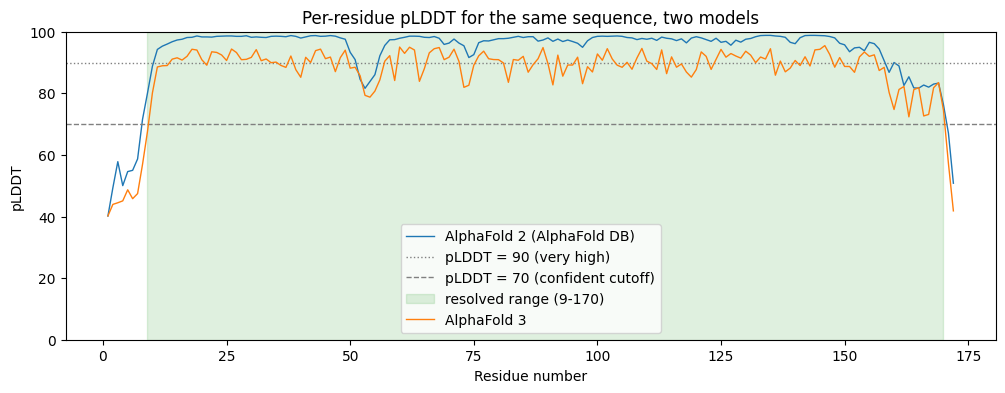

In [136]:
af3_model = read_structure(path=af3_files["model"])
af3_zn = af3_model.select_atoms("resname ZN")
af3_plddt = residue_plddt(structure=af3_model)

# The B-factor column really is the atom pLDDT: checked against the JSON, atom by atom.
print("B-factor column equals atom_plddts:",
      np.allclose(af3_model.tempfactors, af3_confidences["atom_plddts"], atol=0.01))
print(f"Mean pLDDT over 1STD's range {CRYSTAL_START}-{CRYSTAL_END}: "
      f"AlphaFold 2 {core.mean():.1f}, "
      f"AlphaFold 3 {af3_plddt.loc[CRYSTAL_START:CRYSTAL_END].mean():.1f}")
print(f"pLDDT of the zinc: {af3_zn.tempfactors.mean():.1f}")

ax = plot_plddt(confidence=confidence, highlight=(CRYSTAL_START, CRYSTAL_END),
                label="AlphaFold 2 (AlphaFold DB)",
                title="Per-residue pLDDT for the same sequence, two models")
ax.plot(af3_plddt.index, af3_plddt.values, color="tab:orange", lw=1, label="AlphaFold 3")
ax.legend(loc="lower center")
plt.show()

## B.3 Your ligand against your crystal

Superpose the AlphaFold 3 model on your crystal (`PDB_ID`) as the guide's B.3 does. Report
the Cα RMSD, your ligand's RMSD against the crystal pose with how many atoms matched, and the
residues within 4 Å of each pose, as in ex01.

**Then answer:** was your B.1 prediction right? AlphaFold 3 trained on PDB entries released
before 30 September 2021: was yours one? Would a small ligand RMSD prove that your ligand
binds there? What would?

In [ ]:
def ligand_rmsd(model: mda.AtomGroup, reference: mda.AtomGroup) -> tuple[float, int]:
    """RMSD between two poses of one ligand, its atoms paired by chemistry, not by name.

    Both poses must already sit in one frame: nothing is moved here. RDKit reads each pose
    as a molecule, with its bonds found from the distances between atoms, and pairs the two
    wherever element and bonding agree. So atom names and the order in the file do not
    matter, and where the pairing is not unique (the two oxygens of a carboxylate, a ring
    that can flip) the one with the smallest RMSD counts. Hydrogens are left out. If the
    reference holds several copies of the ligand, the nearest one is used. Returns
    (rmsd, atoms paired), or (nan, 0) when the two are not the same molecule.
    """
    molecules = []
    for atoms in (model, reference):
        heavy = mda.Merge(atoms.select_atoms("not type H")).atoms   # a copy, without hydrogens
        heavy.altLocs = [""] * heavy.n_atoms                        # RDKit reads one alternate position
        molecules.append(Chem.MolFromPDBBlock(pdb_text(atoms=heavy), sanitize=False))
    small, large = sorted(molecules, key=lambda molecule: molecule.GetNumAtoms())
    if not large.HasSubstructMatch(small):
        return float("nan"), 0
    return float(rdMolAlign.CalcRMS(small, large)), small.GetNumAtoms()

In [ ]:
# A.3's superposition on the AlphaFold 3 model. Pairing by residue number works because
# the whole UniProt sequence went in: both models and the crystal count the same way.
af3_rmsd, af3_deviation = superpose(mobile=af3_model, reference=crystal)
print(f"Cα RMSD against 3D08 over {len(af3_deviation)} residues: "
      f"AlphaFold 3 {af3_rmsd:.2f} Å, "
      f"AlphaFold 2 {overall_rmsd:.2f} Å")
print("Deviation at the zinc site:",
      af3_deviation[zn_coordinating_residues].round(2).to_dict())

# The zinc moved with the model, so the two poses are already in the crystal's frame.
zinc_error, matched = ligand_rmsd(model=af3_zn, reference=crystal_zn)
print(f"\nPredicted zinc against the show_superposition(reference=crystal, mobile=af3_model,
                   highlight=zn_coordinating_residues, ligand="ZN").show()
print("Green = 3D08 crystal and its zinc. AlphaFold 3's model and its zinc are coloured by "
      "pLDDT, as in A.3.\nThe two zinc spheres overlap almost exactly: rotate the view to "
      "see both.")crystal's: {zinc_error:.2f} Å ({matched} atom matched)")
print("Residues within 2.6 Å of the predicted zinc:",
      af3_model.select_atoms("protein and around 2.6 resname ZN").residues.resids.tolist())
print("Residues within 2.6 Å of the crystal's zinc :", zn_coordinating_residues)

Cα RMSD against 3D08 over 182 residues: AlphaFold 3 0.64 Å, AlphaFold 2 0.76 Å
Deviation at the zinc site: {176: 0.22, 179: 0.44, 238: 0.12, 242: 0.15}

Predicted zinc against the crystal's: 0.20 Å (1 atom matched)
Residues within 2.6 Å of the predicted zinc: [176, 179, 238, 242]
Residues within 2.6 Å of the crystal's zinc : [176, 179, 238, 242]


In [ ]:
show_superposition(reference=crystal, mobile=af3_model,
                   highlight=zn_coordinating_residues, ligand="ZN").show()
print("Green = 3D08 crystal and its zinc. AlphaFold 3's model and its zinc are coloured by "
      "pLDDT, as in A.3.\nThe two zinc spheres overlap almost exactly: rotate the view to "
      "see both.")

---

## Before you submit

- [ ] A.1 prediction **written before** the analysis in A.2, citing your ex01 findings
- [ ] pLDDT plot, PAE heatmap and confidence **composition** for your own protein
- [ ] A.3 comparison done, **or** explicitly explained why it could not be
- [ ] B.1 prediction **written before** your AlphaFold 3 run
- [ ] B.2 AlphaFold 3's confidence reported, with the numbers that concern your ligand
- [ ] B.3 ligand RMSD against your crystal, with the residues around both poses
- [ ] Anything that did not work is **described honestly** rather than deleted: a documented
      dead end earns marks, a silently missing section does not